### Inline Example of Local Expert 'Optimal Interpolation' on Satellite Data


# Using Colab? Then clone and install

#✨ **SETUP: This section checks whether I am using Google Colab.**
If I am, it downloads the GPSat code from GitHub and installs
the Python packages needed to run it.
This is just preparing the software environment.
No sea ice data is being analysed yet.

In [1]:
try:
    import google.colab
    IN_COLAB = True
except:
    IN_COLAB = False

if IN_COLAB:
    import subprocess
    import os
    import re

    # change to working directory
    work_dir = "/content"

    assert os.path.exists(work_dir), f"workspace directory: {work_dir} does not exist"
    os.chdir(work_dir)

    # clone repository
    command = "git clone https://github.com/CPOMUCL/GPSat.git"
    result = subprocess.run(command.split(), capture_output=True, text=True)
    print(result.stdout)

    repo_dir = os.path.join(work_dir, "GPSat")

    print(f"changing directory to: {repo_dir}")
    os.chdir(repo_dir)

    # exclude certain requirements if running on colab - namely avoid installing/upgrading tensorflow
    new_req = []
    with open(os.path.join(repo_dir, "requirements.txt"), "r") as f:
        for line in f.readlines():
            # NOTE: here also removing numpy requirement
            if re.search("^tensorflow|^numpy", line):
                new_req.append("#" + line)
            else:
                new_req.append(line)

    # create a colab specific requirements file
    with open(os.path.join(repo_dir, "requirements_colab.txt"), "w") as f:
        f.writelines(new_req)

    # install the requirements
    command = "pip install -r requirements_colab.txt"
    with subprocess.Popen(command.split(), stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True) as proc:
        # Stream the standard output in real-time
        for line in proc.stdout:
            print(line, end='')

    # install the GPSat pacakge in editable mode
    command = "pip install -e ."
    with subprocess.Popen(command.split(), stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True) as proc:
        # Stream the standard output in real-time
        for line in proc.stdout:
            print(line, end='')

In [2]:
! pip install global-land-mask

In [3]:
%pip install deprecated

Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install dataclasses-json cartopy

Note: you may need to restart the kernel to use updated packages.


In [5]:
!ls /home/srayat/GPSat

configs  examples	 MANIFEST.in	 README.md	   setup.py  venv
data	 GPSat		 notebooks	 requirements.txt  tests
docs	 GPSat.egg-info  pyproject.toml  run_examples.sh   TODO.md


#  Import Packages

#✨**IMPORTS: This section loads the Python libraries and GPSat tools**
 needed for the analysis. These tools help load and organise
satellite data, perform calculations, convert map coordinates,
run spatial interpolation models, and create plots.
No sea ice data is being processed yet.

In [6]:
import GPSat

print("GPSat location:", GPSat.__file__)
print("GPSat search paths:", list(GPSat.__path__))

GPSat location: None
GPSat search paths: ['/home/srayat/GPSat']


In [7]:
import os
import sys

os.chdir("/home/srayat/GPSat")
sys.path.insert(0, "/home/srayat/GPSat")

import GPSat

print("GPSat location:", GPSat.__file__)

GPSat location: None


In [9]:
import os

print(os.listdir("/home/srayat/GPSat/GPSat"))

['__init__.py', 'bin_data.py', 'config_dataclasses.py', 'dataloader.py', 'dataprepper.py', 'datetime_utils.py', 'decorators.py', 'local_experts.py', 'models', 'plot_utils.py', 'postprocessing.py', 'prediction_locations.py', 'read_and_store.py', 'utils.py', 'vff.py', '__pycache__']


In [10]:
import sys

print(sys.path[:8])

['/home/srayat/GPSat', '/home/srayat/GPSat', '/cpnet/software/cpom_software', '/home/srayat/.conda/envs/gpsat/lib/python310.zip', '/home/srayat/.conda/envs/gpsat/lib/python3.10', '/home/srayat/.conda/envs/gpsat/lib/python3.10/lib-dynload', '', '/home/srayat/GPSat/venv/lib/python3.10/site-packages']


In [11]:
import sys
import importlib

sys.modules.pop("GPSat", None)
importlib.invalidate_caches()

import GPSat

print("GPSat location:", GPSat.__file__)

GPSat location: /home/srayat/GPSat/GPSat/__init__.py


In [12]:

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from global_land_mask import globe
from GPSat import get_data_path, get_parent_path
from GPSat.dataprepper import DataPrep
from GPSat.dataloader import DataLoader
from GPSat.utils import stats_on_vals, WGS84toEASE2, EASE2toWGS84, cprint, grid_2d_flatten, get_weighted_values
from GPSat.local_experts import LocalExpertOI, get_results_from_h5file
from GPSat.plot_utils import plot_wrapper, plot_pcolormesh, get_projection, plot_pcolormesh_from_results_data, plot_hyper_parameters
from GPSat.postprocessing import smooth_hyperparameters

2026-10-18 20:14:27.180564: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-18 20:14:27.180657: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-18 20:14:27.256652: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-18 20:14:27.319139: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-18 20:14:37.368731: W tensorflow/comp

# Parameters

#✨**Model configuration**
This section defines the geographical area and spatial settings used by GPSat. The model is configured for the Arctic, using the North Pole as the coordinate reference. Local models (called experts) are positioned 200 km apart across a 1,000 km × 1,000 km region. Each expert learns from satellite observations within 300 km and makes predictions within 200 km. Predictions are calculated on a grid with 5 km spacing. Finally, the map settings are defined for displaying Arctic results. These parameters control how the satellite data will be used to reconstruct spatial patterns, but no modelling has happened yet.


One thing worth remembering for project:
The 5 km grid spacing is not necessarily the true resolution of the reconstructed sea ice information. That's particularly important when evaluating whether GPSat captures short-term variability.

In [13]:

# NOTE: there are parameters values that are set inline in the cells below

# lat,lon center (origin) used for converting between WGS84 and EASE2 projections
lat_0 = 90
lon_0 = 0

# expert location parameters
# spacing between experts (laid out on a grid), in meters
expert_spacing = 200_000
# range of experts, from origin, in meters
# expert_x_range = [-750_000.0, 1000_000.0]
# expert_y_range = [-500_000.0, 1250_000.0]
expert_x_range = [-500_000, 500_000]
expert_y_range = [-500_000, 500_000]

# prediction spacing
# (below predictions same range as experts)
pred_spacing = 5_000


# model parameters
# Set training and inference radius
# - distance observations need to be away from expert locations to be included in training
training_radius = 300_000  # 300km
# - distance prediction locations need to be away from expert locations in order of predictions to be made
inference_radius = 200_000  # 200km


# plotting
# extent = [lon min, lat max, lat min, lat max]
extent = [-180, 180, 60, 90]

# which projection to use: "north" or "south"
projection = "north"

#  read in raw data

add each key in col_func as a column, using a specified function + arguments
values are unpacked and passed to GPSat.utils.config_func

#✨**Loading and preparing satellite observations**
This section loads example observational data from CSV files into a table called df. It records which file each observation came from, then converts latitude and longitude into x and y coordinates measured in metres so the model can calculate distances. It also converts observation dates into numerical values representing days. This prepares the data for spatial and potentially temporal modelling, but no interpolation or predictions have been made yet.


**Scientific takeaway:** This is the first step towards using real observations to investigate sea ice variability. The model needs to know where and when each observation was collected before it can reconstruct patterns between observations.

In [14]:
import os

example_path = get_data_path("example")
print("Example data folder:", example_path)
print("Files:", os.listdir(example_path))

Example data folder: /home/srayat/GPSat/data/example
Files: ['A_RAW.csv', 'B_RAW.csv', 'C_RAW.csv']


In [15]:


df = DataLoader.read_flat_files(file_dirs=get_data_path("example"),
                                file_regex="_RAW\.csv$",
                                col_funcs={
                                    "source": {
                                        "func": lambda x: re.sub('_RAW.*$', '', os.path.basename(x)),
                                        "filename_as_arg": True
                                    }
                                })

# convert lon, lat, datetime to x, y, t - to be used as the coordinate space
df['x'], df['y'] = WGS84toEASE2(lon=df['lon'], lat=df['lat'], lat_0=lat_0, lon_0=lon_0)
df['t'] = df['datetime'].values.astype("datetime64[D]").astype(float)

----------------------------------------------------------------------------------------------------
reading files from:
/home/srayat/GPSat/data/example/
that match regular expression: _RAW\.csv$
'read_from_multiple_files': 1.264 seconds


In [16]:
df.head()

,lon,lat,datetime,z,source,x,y,t
0,-57.190860,65.647048,2020-03-01 00:03:32.948838,0.0330,A,-2.267682e+06,-1.461934e+06,18322.0
1,-57.224372,65.679991,2020-03-01 00:03:36.667280,0.1057,A,-2.265518e+06,-1.458663e+06,18322.0
2,-57.227168,65.682736,2020-03-01 00:03:37.198486,0.0004,A,-2.265338e+06,-1.458391e+06,18322.0
3,-57.229965,65.685481,2020-03-01 00:03:37.729692,0.0510,A,-2.265157e+06,-1.458118e+06,18322.0
4,-57.232762,65.688226,2020-03-01 00:03:38.260898,0.0382,A,-2.264977e+06,-1.457846e+06,18322.0


# stats on data

#✨**Checking the distribution of observations**
This section examines the values in the z column of the dataset and calculates summary statistics, including different percentiles. This helps identify unusually high or low measurements that might need checking or filtering before modelling. The purpose is to understand the range and distribution of the observations and assess their quality. No data is removed at this stage.

Scientific takeaway: Before modelling satellite observations, we need to understand their distribution and identify potential errors without accidentally removing genuine physical variability.

In [17]:

print("*" * 20)
print("summary / stats table on metric (use for trimming)")

val_col = 'z'
vals = df[val_col].values
stats_df = stats_on_vals(vals=vals, name=val_col,
                         qs=[0.01, 0.05] + np.arange(0.1, 1.0, 0.1).tolist() + [0.95, 0.99])

print(stats_df)

********************
summary / stats table on metric (use for trimming)
'stats_on_vals': 0.312 seconds
                      z
measure               z
size            1174848
num_not_nan     1174848
num_inf               0
min            -16.7965
mean           0.128416
max             16.7093
std            0.186566
skew         -10.912819
kurtosis     890.268297
q0.010          -0.3732
q0.050          -0.1387
q0.100          -0.0485
q0.200           0.0322
q0.300           0.0767
q0.400           0.1101
q0.500           0.1394
q0.600           0.1686
q0.700           0.2011
q0.800           0.2424
q0.900           0.3067
q0.950           0.3632
q0.990           0.4775


# visualise data

#✨**Visualising the observations**
This section plots the satellite observations on an Arctic map and creates a histogram showing the distribution of measurement values. The map helps identify where observations were collected, gaps in coverage and geographical patterns, while the histogram shows which values are most common and whether extreme measurements exist. The colour scale is set between −0.1 and 0.5, and up to 500,000 observations are displayed. This helps assess the data before modelling, but no interpolation has been performed yet.

Scientific takeaway: We're checking what the original observations look like before using GPSat to reconstruct values in areas where measurements are missing.

In [18]:
import cartopy
import cartopy.crs as ccrs

print("Cartopy version:", cartopy.__version__)
print("Projection:", ccrs.NorthPolarStereo())

Cartopy version: 0.22.0
Projection: +proj=stere +ellps=WGS84 +lat_0=90 +lon_0=0.0 +x_0=0.0 +y_0=0.0 +no_defs +type=crs


'stats_on_vals': 0.355 seconds
there were too many points 1174848>max_obs: 500000
selecting 42.64% (500992) points at random for raw data plot
plotting pcolormesh...
'plot_pcolormesh': 0.305 seconds
plotting hist (using all data)...
'plot_hist': 2.525 seconds
'plot_wrapper': 3.789 seconds


/home/srayat/GPSat/venv/lib/python3.10/site-packages/cartopy/io/__init__.py:241: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/home/srayat/GPSat/venv/lib/python3.10/site-packages/cartopy/io/__init__.py:241: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/home/srayat/GPSat/venv/lib/python3.10/site-packages/cartopy/io/__init__.py:241: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_lakes.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


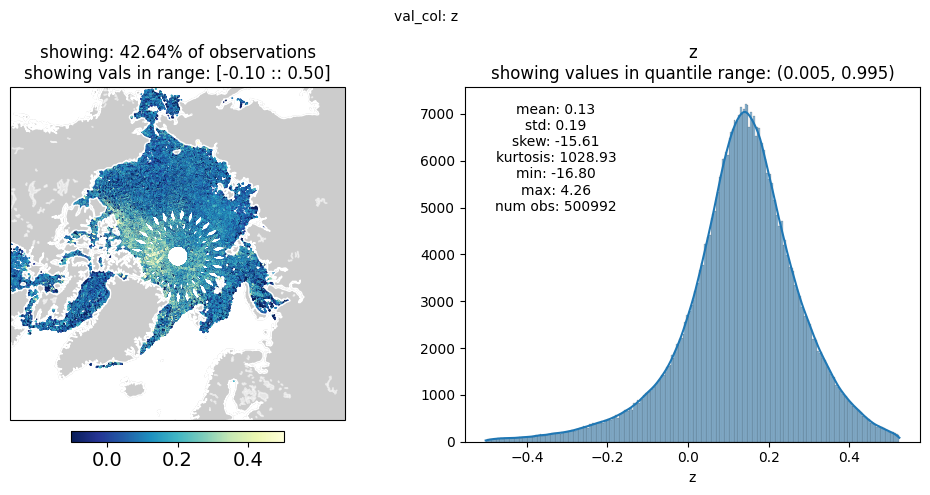

In [19]:

# plot observations and histogram
fig, stats_df = plot_wrapper(plt_df=df,
                             val_col=val_col,
                             max_obs=500_000,
                             vmin_max=[-0.1, 0.5],
                             projection=projection,
                             extent=extent)

plt.show()

# bin raw data
bin by date, source - returns a DataSet

#✨**Filtering and gridding the observations**
This section removes observations with z values outside −0.35 to 0.65 and groups the remaining measurements into 50 km × 50 km grid cells. Observations from different days and data sources are kept separate. This reduces the number of individual measurements and organises them into a regular spatial grid, making the data easier to model. The gridded dataset is then converted back into a table, with empty grid cells removed. Binning may smooth out small-scale variability, which is important to consider when evaluating sea ice reconstructions.

Scientific takeaway: You're moving from individual satellite measurements to a more manageable gridded dataset. This makes modelling easier, but some fine-scale spatial information may be lost

In [20]:

bin_ds = DataPrep.bin_data_by(df=df.loc[(df['z'] > -0.35) & (df['z'] < 0.65)],
                              by_cols=['t', 'source'],
                              val_col=val_col,
                              x_col='x',
                              y_col='y',
                              grid_res=50_000,
                              x_range=[-4500_000.0, 4500_000.0],
                              y_range=[-4500_000.0, 4500_000.0])

# convert bin data to DataFrame
# - removing all the nans that would be added at grid locations away from data
bin_df = bin_ds.to_dataframe().dropna().reset_index()

'bin_data_by': 1.835 seconds


# plot binned data

#✨**Visualising the processed observations**
This section converts the gridded coordinates back into latitude and longitude so the data can be plotted on an Arctic map. It then displays the filtered, 50 km gridded observations and a histogram of their values. This allows us to compare the processed dataset with the original observations and check how filtering and binning have affected the spatial patterns and distribution of measurements. Some points may overlap because observations from different days and sources can occupy the same grid cell. No interpolation has happened yet.

Scientific takeaway: We're checking what the data look like after preprocessing but before modelling. This is important because the quality and resolution of the input data influence what the model can reconstruct.

'stats_on_vals': 0.016 seconds
plotting pcolormesh...
'plot_pcolormesh': 0.043 seconds
plotting hist (using all data)...
'plot_hist': 0.255 seconds
'plot_wrapper': 0.385 seconds


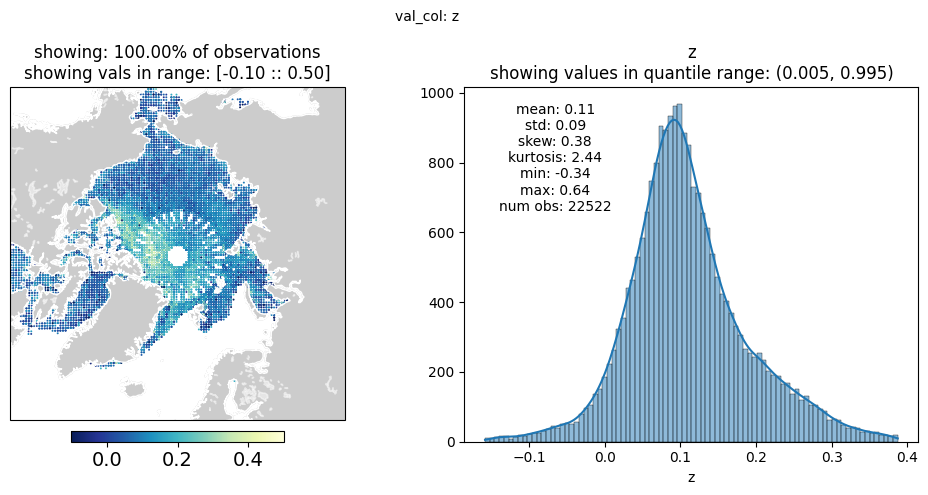

In [21]:

# this will plot all observations, some on top of each other
bin_df['lon'], bin_df['lat'] = EASE2toWGS84(bin_df['x'], bin_df['y'],
                                            lat_0=lat_0, lon_0=lon_0)

# plot observations and histogram
fig, stats_df = plot_wrapper(plt_df=bin_df,
                             val_col=val_col,
                             max_obs=500_000,
                             vmin_max=[-0.1, 0.5],
                             projection=projection,
                             extent=extent)

plt.show()

# expert locations
on evenly spaced grid

#✨**Creating local expert locations**
This section creates a regular grid of locations where GPSat's local models, called experts, will be positioned. The experts are spaced 200 km apart across the selected region. Their x and y coordinates are stored in a table called eloc, and each expert is assigned the same time coordinate based on the average observation date, rounded down to a whole day. These locations define where the local models will operate, but no models have been trained yet.

Scientific takeaway: GPSat divides the modelling problem into smaller geographical areas, with local experts learning from nearby observations rather than relying on one model for the entire region. 💙

In [22]:

xy_grid = grid_2d_flatten(x_range=expert_x_range,
                          y_range=expert_y_range,
                          step_size=expert_spacing)

# store in dataframe
eloc = pd.DataFrame(xy_grid, columns=['x', 'y'])

# add a time coordinate
eloc['t'] = np.floor(df['t'].mean())

In [24]:
#showing first 5 expert locations
eloc.head()

,x,y,t
0,-400000.0,-400000.0,18326.0
1,-200000.0,-400000.0,18326.0
2,0.0,-400000.0,18326.0
3,200000.0,-400000.0,18326.0
4,400000.0,-400000.0,18326.0


# plot expert locations

#✨Plotting the local expert locations
This section converts the local expert coordinates into latitude and longitude and plots them as dots on an Arctic map. It allows us to check where the GPSat models will be positioned and whether they cover the intended study region. All experts have the same assigned time coordinate, so the map is mainly showing their geographical locations rather than temporal differences. No model training or predictions have happened yet.

Scientific takeaway: We're checking that the local models are positioned in the correct geographical area before running GPSat. 💙

'plot_pcolormesh': 0.045 seconds


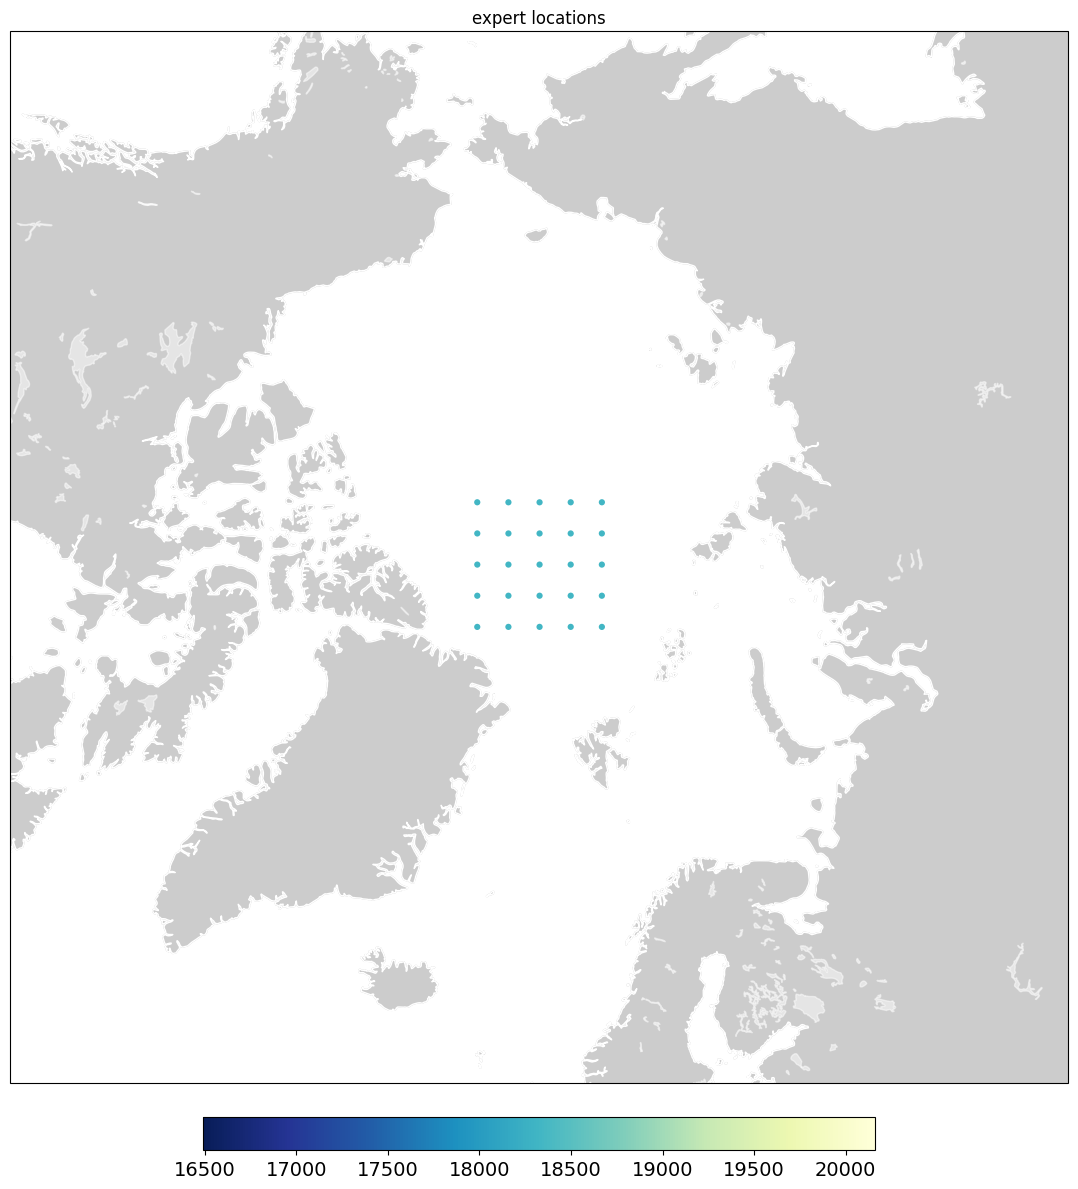

In [25]:

eloc['lon'], eloc['lat'] = EASE2toWGS84(eloc['x'], eloc['y'],
                                        lat_0=lat_0, lon_0=lon_0)

fig = plt.figure(figsize=(12, 12))
ax = fig.add_subplot(1, 1, 1, projection=get_projection(projection))

plot_pcolormesh(ax=ax,
                lon=eloc['lon'],
                lat=eloc['lat'],
                plot_data=eloc['t'],
                title="expert locations",
                scatter=True,
                s=20,
                fig=fig,
                extent=extent)

plt.tight_layout()
plt.show()

# prediction locations

#✨**Creating ocean-only prediction locations**
This section creates a fine grid of locations where GPSat will eventually predict values. Prediction points are spaced 5 km apart across the selected region, compared with the 200 km spacing between local experts. The coordinates are converted into latitude and longitude, and a land mask is used to identify which points are over ocean. Locations over land are removed because the model is intended to predict sea ice-related values over water. No predictions have been made yet; this section only defines where predictions will occur.

Scientific takeaway: We're defining the locations where GPSat will reconstruct the missing observational information. The 5 km grid provides closely spaced estimates, but the true spatial detail depends on the observations and modelling method, not just the prediction spacing. 💙

In [26]:

pred_xy_grid = grid_2d_flatten(x_range=expert_x_range,
                               y_range=expert_y_range,
                               step_size=pred_spacing)

# store in dataframe
# NOTE: the missing 't' coordinate will be determine by the expert location
# - alternatively the prediction location can be specified
ploc = pd.DataFrame(pred_xy_grid, columns=['x', 'y'])

ploc['lon'], ploc['lat'] = EASE2toWGS84(ploc['x'], ploc['y'],
                                        lat_0=lat_0, lon_0=lon_0)

# identify if a position is in the ocean (water) or not
ploc["is_in_ocean"] = globe.is_ocean(ploc['lat'], ploc['lon'])

# keep only prediction locations in ocean
ploc = ploc.loc[ploc["is_in_ocean"]]

In [27]:
print("Number of expert locations:", len(eloc))
print("Number of ocean prediction locations:", len(ploc))

Number of expert locations: 25
Number of ocean prediction locations: 40000


# plot prediction locations

#✨**Plotting the prediction locations**
This section plots the 5 km prediction grid on an Arctic map to show where GPSat will eventually estimate values. Each prediction location is displayed as a very small dot, with all points assigned the same placeholder value for visualisation. Land locations have already been removed, so the map should show only ocean prediction points. This allows us to check that the prediction grid covers the intended geographical region before running the model. No actual predictions have been made yet.

Scientific takeaway: We're checking where the reconstructed satellite values will be produced, rather than examining actual observations or model results. 💙

'plot_pcolormesh': 0.039 seconds


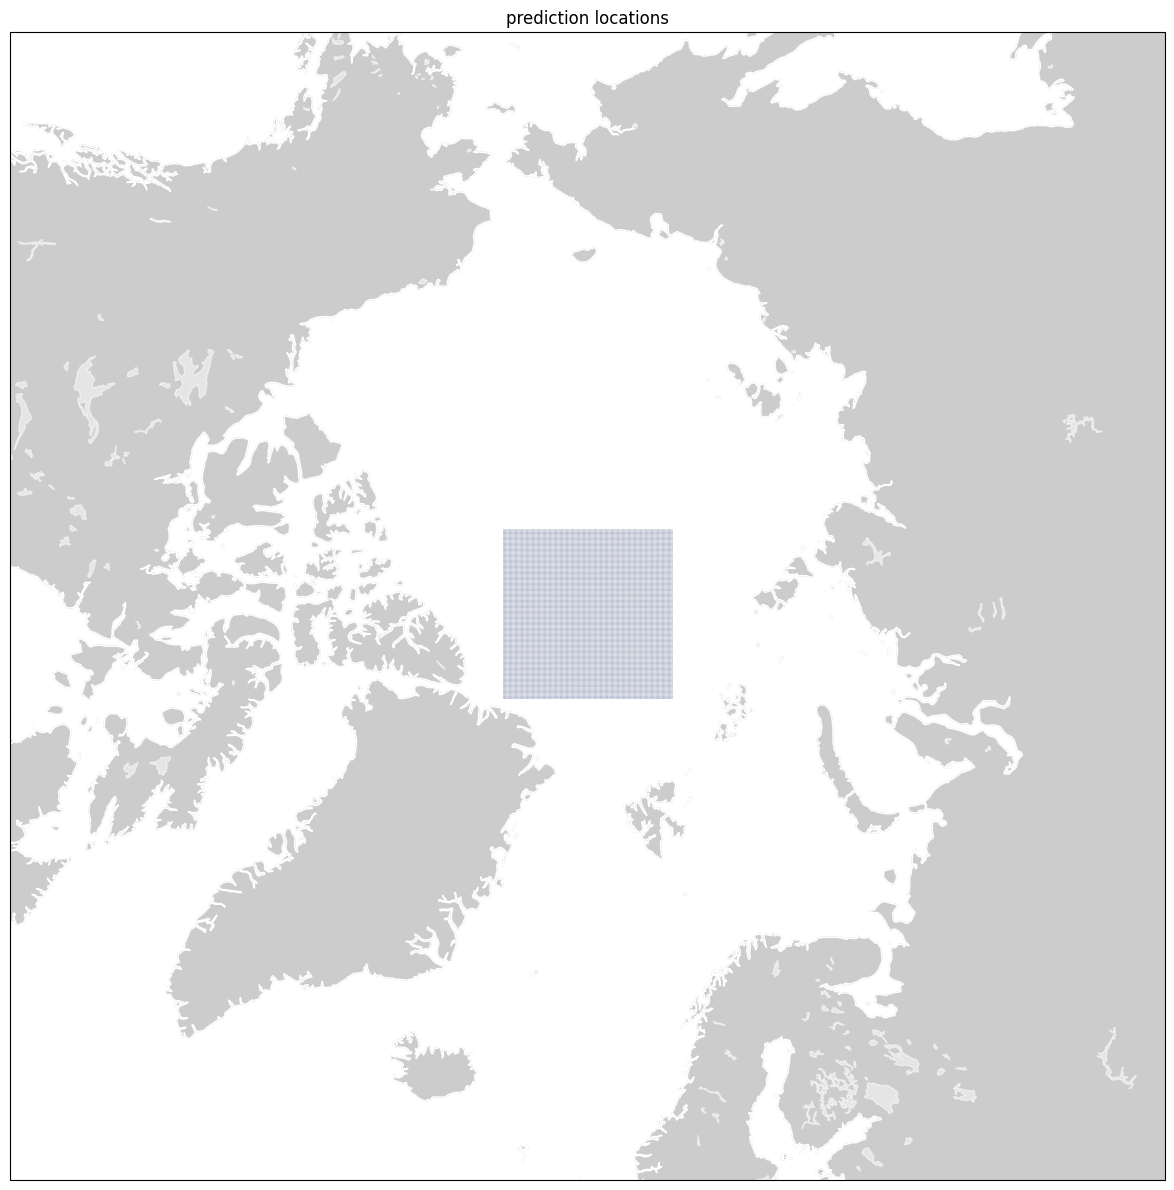

In [28]:

fig = plt.figure(figsize=(12, 12))
ax = fig.add_subplot(1, 1, 1, projection=get_projection(projection))

plot_pcolormesh(ax=ax,
                lon=ploc['lon'],
                lat=ploc['lat'],
                plot_data=np.full(len(ploc), 1.0),  # np.arange(len(ploc)),
                title="prediction locations",
                scatter=True,
                s=0.1,
                # fig=fig,
                extent=extent)

plt.tight_layout()
plt.show()

# configurations:

#✨**Configuring the GPSat machine-learning model**
This section defines how GPSat will use the observations to make predictions. It uses the filtered, 50 km gridded data and considers both geographical position and time. Each local expert selects observations within 300 km and approximately four days before or after its assigned date. The model uses Gaussian Process Regression to learn spatial and temporal patterns and estimate values where observations are missing. The lengthscale settings control how rapidly the model can represent changes across space and time, while the likelihood variance accounts for observational noise. Finally, predictions will be made at the predefined 5 km ocean locations within 200 km of each expert. This section only sets up the model; training and prediction have not happened yet.

Scientific takeaway: This is where your dissertation's central question becomes especially relevant. GPSat must use assumptions about how sea ice measurements vary across space and time to fill observational gaps. Your comparison with SWOT can help test whether those assumptions reproduce real short-term changes or smooth them away.

In [29]:

# observation data
data = {
    "data_source": bin_df,
    "obs_col": "z",
    "coords_col": ["x", "y", "t"],
    # selection criteria used for each local expert
    "local_select": [
        {
            "col": "t",
            "comp": "<=",
            "val": 4
        },
        {
            "col": "t",
            "comp": ">=",
            "val": -4
        },
        {
            "col": [
                "x",
                "y"
            ],
            "comp": "<",
            "val": training_radius
        }
    ]
}

# local expert locations
local_expert = {
    "source": eloc
}

# model
model = {
    "oi_model": "GPflowGPRModel",
    "init_params": {
        # scale (divide) coordinates
        "coords_scale": [50000, 50000, 1],
        # can specify initial parameters values for model:
        # "noise_variance": 0.10,
        # "kernel_kwargs": {
        #     "lengthscales": [2.0, 2.0, 1.0],
        #     "variance": 0.05
        # }
    },
    # keyword arguments to be passed into each model/local expert's optimise_parameters method
    "optim_kwargs": {
        # parameters to be fixed (not trainable)
        # "fixed_params": ["likelihood_variance"]
    },
    "constraints": {
        # lengthscales - same order coord_col (see data)
        # - given in unscaled units
        "lengthscales": {
            "low": [1e-08, 1e-08, 1e-08],
            "high": [600000, 600000, 9]
        },
        "likelihood_variance": {
            "low": 0.00125,
            "high": 0.01
        }
    }
}

# prediction locations
pred_loc = {
    "method": "from_dataframe",
    "df": ploc,
    "max_dist": inference_radius
}

# Local Expert OI

if process falls over here when calling run(), try: Runtime -> "Restart and run all"

#✨**Running the GPSat model**
This section creates the GPSat model using the observation data, local expert locations, Gaussian Process settings and prediction grid defined earlier. It chooses an HDF5 file where the results will be saved and deletes any previous file with the same name. The model is then run with parameter optimisation enabled, meaning each local expert fits its statistical parameters to nearby observations. GPSat uses these models to estimate values at prediction locations and saves the results for later analysis. This is the stage where the actual interpolation and modelling take place.

Scientific takeaway: GPSat is now using observations to learn patterns across space and time and reconstruct values where measurements are missing. The next important step will be examining the results, including their uncertainty, and eventually testing how accurately they capture variability using independent observations.

In [ ]:
#%pip install gpflow
#!grep -inE "gpflow|tensorflow|probability" /content/GPSat/requirements*.txt /content/GPSat/setup.py

#import gpflow
#print("GPflow version:", gpflow.__version__)

In [30]:
import gpflow

print("GPflow version:", gpflow.__version__)

GPflow version: 2.11.2


In [31]:
store_path = get_parent_path("results", "inline_example.h5")
print("Results file:", store_path)
print("Already exists:", os.path.exists(store_path))

Results file: /home/srayat/GPSat/results/inline_example.h5
Already exists: False


In [32]:

locexp = LocalExpertOI(expert_loc_config=local_expert,
                       data_config=data,
                       model_config=model,
                       pred_loc_config=pred_loc)

# run optimal interpolation
# - no predictions locations supplied
store_path = get_parent_path("results", "inline_example.h5")

# for the purposes of a simple example, if store_path exists: delete it
if os.path.exists(store_path):
    cprint(f"removing: {store_path}", "FAIL")
    os.remove(store_path)

# run optimal interpolation
locexp.run(store_path=store_path,
           optimise=True,
           check_config_compatible=False)

'data_select': 0.002 seconds
'load': 0.002 seconds
in json_serializable - key: 'data_source' has value DataFrame/Series, but is too long: 22522 >  100
storing as str
in json_serializable - key: 'df' has value DataFrame/Series, but is too long: 40000 >  100
storing as str
---------
storing expert locations in 'expert_locs' table
exception occurred: 'No object named expert_locs in the file'
will now close object

---------
dropping expert locations that already exists in 'run_details' table
exception occurred: 'No object named run_details in the file'
will now close object

--------------------------------------------------
1 / 25
current local expert:
          x         y        t   lon        lat
0 -400000.0 -400000.0  18326.0 -45.0  84.933616
'data_select': 0.005 seconds
'load': 0.005 seconds
'local_data_select': 0.016 seconds
number obs: 402
setting lengthscales to: [1. 1. 1.]
'__init__': 0.154 seconds
'get_parameters': 0.008 seconds
'set_lengthscales_constraints': 0.009 seconds
'se

results are store in hdf5

#✨**Loading the GPSat results**
This section opens the HDF5 file containing the results from the GPSat model. It extracts the saved results tables into a dictionary called dfs and retrieves the model configuration as oi_config. It then prints the names of the available tables so we can see what outputs were produced. No new modelling is performed; this is the first step in examining the results.

Scientific takeaway: We've finished running the model and are now accessing its outputs to understand what GPSat predicted and how the model behaved.

In [33]:

# extract, store in dict
dfs, oi_config = get_results_from_h5file(store_path)

print(f"tables in results file: {list(dfs.keys())}")

reading in results
getting all tables
merging on expert location data
table: 'oi_config' does not have all coords_col: ['x', 'y', 't'] in columns, not merging on expert_locations
tables in results file: ['expert_locs', 'kernel_variance', 'lengthscales', 'likelihood_variance', 'oi_config', 'preds', 'run_details']


In [34]:
dfs["preds"].head()

,x,y,t,_dim_0,f*,f*_var,y_var,f_bar,pred_loc_x,pred_loc_y,pred_loc_t,lon,lat
0,-400000.0,-400000.0,18326.0,0,0.160926,0.000552,0.003878,0,-497500.0,-497500.0,18326.0,-45.0,84.933616
1,-400000.0,-400000.0,18326.0,1,0.162821,0.000549,0.003876,0,-492500.0,-497500.0,18326.0,-45.0,84.933616
2,-400000.0,-400000.0,18326.0,2,0.165080,0.000548,0.003874,0,-487500.0,-497500.0,18326.0,-45.0,84.933616
3,-400000.0,-400000.0,18326.0,3,0.167681,0.000547,0.003874,0,-482500.0,-497500.0,18326.0,-45.0,84.933616
4,-400000.0,-400000.0,18326.0,4,0.170596,0.000548,0.003874,0,-477500.0,-497500.0,18326.0,-45.0,84.933616


In [35]:
print("Total predictions:", len(dfs["preds"]))
print("Unique prediction locations:",
      dfs["preds"][["pred_loc_x", "pred_loc_y"]].drop_duplicates().shape[0])

Total predictions: 106464
Unique prediction locations: 40000


Plot Hyper Parameters

#✨**Visualising GPSat hyperparameters**
This section plots the hyperparameters learned by GPSat during model training. These include spatial and temporal lengthscales, kernel variance and likelihood variance. Lengthscales describe how quickly observations become less correlated across distance and time, while kernel variance describes the amplitude of variability represented by the model. Likelihood variance accounts for observational noise or unexplained variation. The parameters are displayed on Arctic maps to investigate how the model's statistical behaviour varies between local experts. The colour scales use the 1st and 99th percentiles to reduce the influence of extreme values.

Scientific takeaway: These plots help us understand how GPSat represents spatial and temporal variability, which is important when evaluating whether its reconstructed maps preserve genuine short-term sea ice changes.

'data_select': 0.001 seconds
'load': 0.002 seconds
'data_select': 0.001 seconds
'load': 0.002 seconds
'data_select': 0.001 seconds
'load': 0.002 seconds
'data_select': 0.000 seconds
'load': 0.001 seconds
'data_select': 0.000 seconds
'load': 0.001 seconds
'data_select': 0.000 seconds
'load': 0.001 seconds
'plot_pcolormesh': 0.035 seconds
'data_select': 0.000 seconds
'load': 0.001 seconds
'plot_pcolormesh': 0.026 seconds
'data_select': 0.000 seconds
'load': 0.001 seconds
'plot_pcolormesh': 0.024 seconds
'data_select': 0.000 seconds
'load': 0.001 seconds
'plot_pcolormesh': 0.021 seconds
'data_select': 0.000 seconds
'load': 0.001 seconds
'plot_pcolormesh': 0.019 seconds


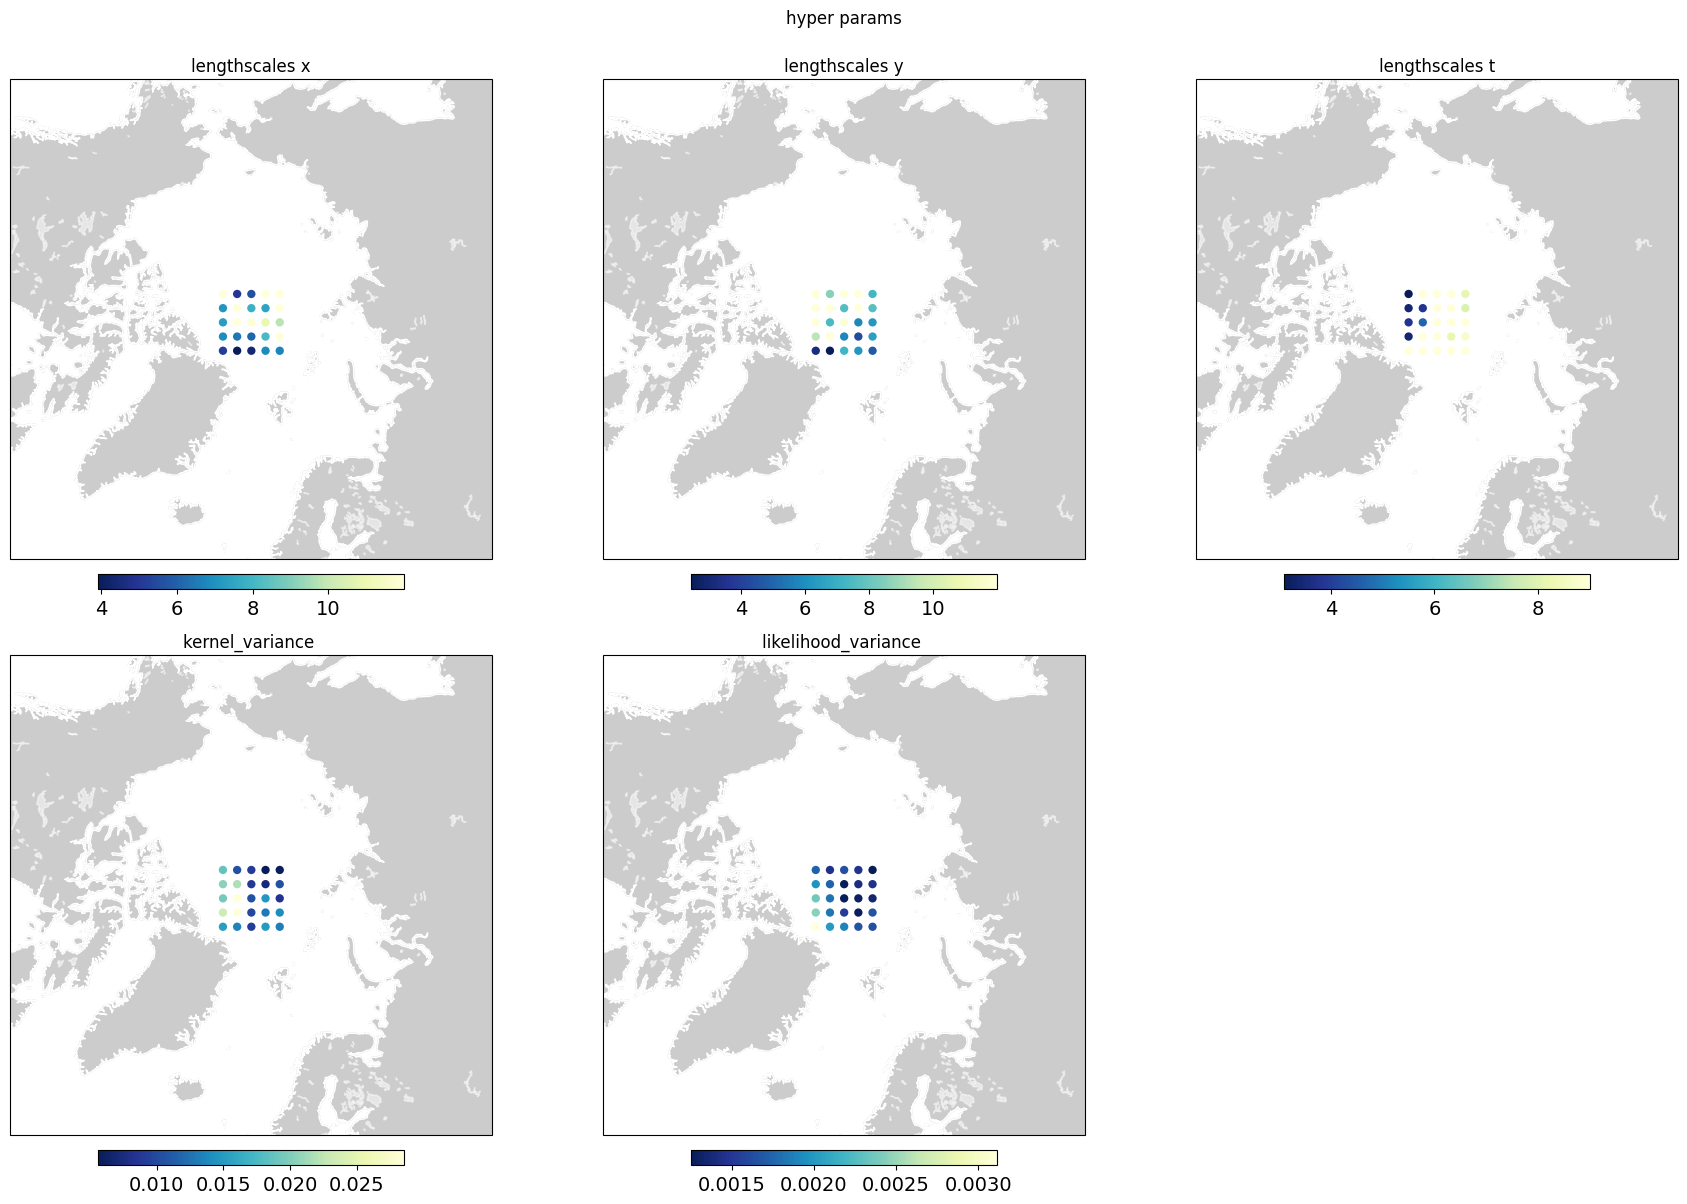

In [36]:

# a template to be used for each created plot config
plot_template = {
    "plot_type": "heatmap",
    "x_col": "x",
    "y_col": "y",
    # use a northern hemisphere projection, centered at (lat,lon) = (90,0)
    "subplot_kwargs": {"projection": projection},
    "lat_0": lat_0,
    "lon_0": lon_0,
    # any additional arguments for plot_hist
    "plot_kwargs": {
        "scatter": True,
    },
    # lat/lon_col needed if scatter = True
    # TODO: remove the need for this
    "lat_col": "lat",
    "lon_col": "lon",
}

fig = plot_hyper_parameters(dfs,
                            coords_col=oi_config[0]['data']['coords_col'],  # ['x', 'y', 't']
                            row_select=None,  # this could be used to select a specific date in results data
                            table_names=["lengthscales", "kernel_variance", "likelihood_variance"],
                            plot_template=plot_template,
                            plots_per_row=3,
                            suptitle="hyper params",
                            qvmin=0.01,
                            qvmax=0.99)

plt.show()

Smooth Hyper Parameters

#✨**Smoothing GPSat hyperparameters and rerunning predictions**
This section smooths the hyperparameters learned by the local Gaussian Process models to make them more spatially consistent. The parameters being smoothed are the spatial and temporal lengthscales, kernel variance and likelihood variance. A smoothing kernel with characteristic lengthscales of 200 km in both horizontal directions is applied across neighbouring expert locations. The smoothed parameters are saved in new tables ending with _SMOOTHED. GPSat is then run again, this time loading the smoothed hyperparameters instead of optimising new ones, and generating predictions using these settings. The original results are retained for comparison.

Scientific takeaway: Smoothing the model's hyperparameters can reduce artificial differences between neighbouring local models, potentially producing more consistent reconstructions. However, it may also suppress genuine spatial differences, making it important to evaluate the resulting predictions against independent observations.

In [37]:

smooth_config = {
    # get hyper parameters from the previously stored results
    "result_file": store_path,
    # store the smoothed hyper parameters in the same file
    "output_file": store_path,
    # get the hyper params from tables ending with this suffix ("" is default):
    "reference_table_suffix": "",
    # newly smoothed hyper parameters will be store in tables ending with table_suffix
    "table_suffix": "_SMOOTHED",
    # dimension names to smooth over
    "xy_dims": [
        "x",
        "y"
    ],
    # parameters to smooth
    "params_to_smooth": [
        "lengthscales",
        "kernel_variance",
        "likelihood_variance"
    ],
    # length scales for the kernel smoother in each dimension
    # - as well as any min/max values to apply
    "smooth_config_dict": {
        "lengthscales": {
            "l_x": 200_000,
            "l_y": 200_000
        },
        "likelihood_variance": {
            "l_x": 200_000,
            "l_y": 200_000,
            "max": 0.3
        },
        "kernel_variance": {
            "l_x": 200_000,
            "l_y": 200_000,
            "max": 0.1
        }
    },
    "save_config_file": True
}

smooth_result_config_file = smooth_hyperparameters(**smooth_config)

# modify the model configuration to include "load_params"
model_load_params = model.copy()
model_load_params["load_params"] = {
    "file": store_path,
    "table_suffix": smooth_config["table_suffix"]
}

locexp_smooth = LocalExpertOI(expert_loc_config=local_expert,
                              data_config=data,
                              model_config=model_load_params,
                              pred_loc_config=pred_loc)

# run optimal interpolation (again)
# - this time don't optimise hyper parameters, but make predictions
# - store results in new tables ending with '_SMOOTHED'
locexp_smooth.run(store_path=store_path,
                  optimise=False,
                  predict=True,
                  table_suffix=smooth_config['table_suffix'],
                  check_config_compatible=False)

found model_name: GPflowGPRModel
setting lengthscales to: [1.]
'__init__': 0.071 seconds
reading in results
selecting only tables: ['lengthscales', 'kernel_variance', 'likelihood_variance']
'data_select': 0.001 seconds
'load': 0.001 seconds
expert_locations data will not be merged on results data
adding smoothed table: lengthscales_SMOOTHED
adding smoothed table: kernel_variance_SMOOTHED
adding smoothed table: likelihood_variance_SMOOTHED
writing (smoothed) hyper parameters to:
/home/srayat/GPSat/results/inline_example.h5
table_suffix:_SMOOTHED
writing: lengthscales_SMOOTHED to table
writing: kernel_variance_SMOOTHED to table
writing: likelihood_variance_SMOOTHED to table
writing config (to use to make predictions with smoothed values) to:
/home/srayat/GPSat/results/inline_example_SMOOTHED.json
'data_select': 0.000 seconds
'load': 0.000 seconds
in json_serializable - key: 'data_source' has value DataFrame/Series, but is too long: 22522 >  100
storing as str
in json_serializable - key: 

# Plot Smoothed Hyper Parameters

#✨**Visualising the smoothed GPSat hyperparameters**
This section reloads the GPSat results and plots the spatially smoothed hyperparameters saved in tables ending with _SMOOTHED. These include the spatial and temporal lengthscales, kernel variance and likelihood variance. The plots allow us to compare the smoothed parameters with the original values and investigate whether smoothing has reduced abrupt differences between neighbouring local experts. The results are displayed on Arctic maps using the same plotting configuration as before. No new model training or predictions occur in this section.

Scientific takeaway: Comparing the original and smoothed hyperparameters helps us understand how spatial smoothing changes the model's assumptions about variability. However, whether this improves the reconstruction must ultimately be tested against independent satellite observations.

Something worth remembering: You're currently examining how GPSat models the data, not yet how accurately GPSat reconstructs the sea ice. That distinction will be important when writing your dissertation methodology and results.

reading in results
getting all tables
merging on expert location data
table: 'oi_config' does not have all coords_col: ['x', 'y', 't'] in columns, not merging on expert_locations
table: 'oi_config_SMOOTHED' does not have all coords_col: ['x', 'y', 't'] in columns, not merging on expert_locations
'data_select': 0.000 seconds
'load': 0.001 seconds
'data_select': 0.000 seconds
'load': 0.001 seconds
'data_select': 0.000 seconds
'load': 0.000 seconds
'data_select': 0.000 seconds
'load': 0.001 seconds
'data_select': 0.000 seconds
'load': 0.001 seconds
'data_select': 0.000 seconds
'load': 0.001 seconds
'plot_pcolormesh': 0.017 seconds
'data_select': 0.000 seconds
'load': 0.001 seconds
'plot_pcolormesh': 0.016 seconds
'data_select': 0.000 seconds
'load': 0.001 seconds
'plot_pcolormesh': 0.016 seconds
'data_select': 0.000 seconds
'load': 0.001 seconds
'plot_pcolormesh': 0.016 seconds
'data_select': 0.000 seconds
'load': 0.001 seconds
'plot_pcolormesh': 0.017 seconds


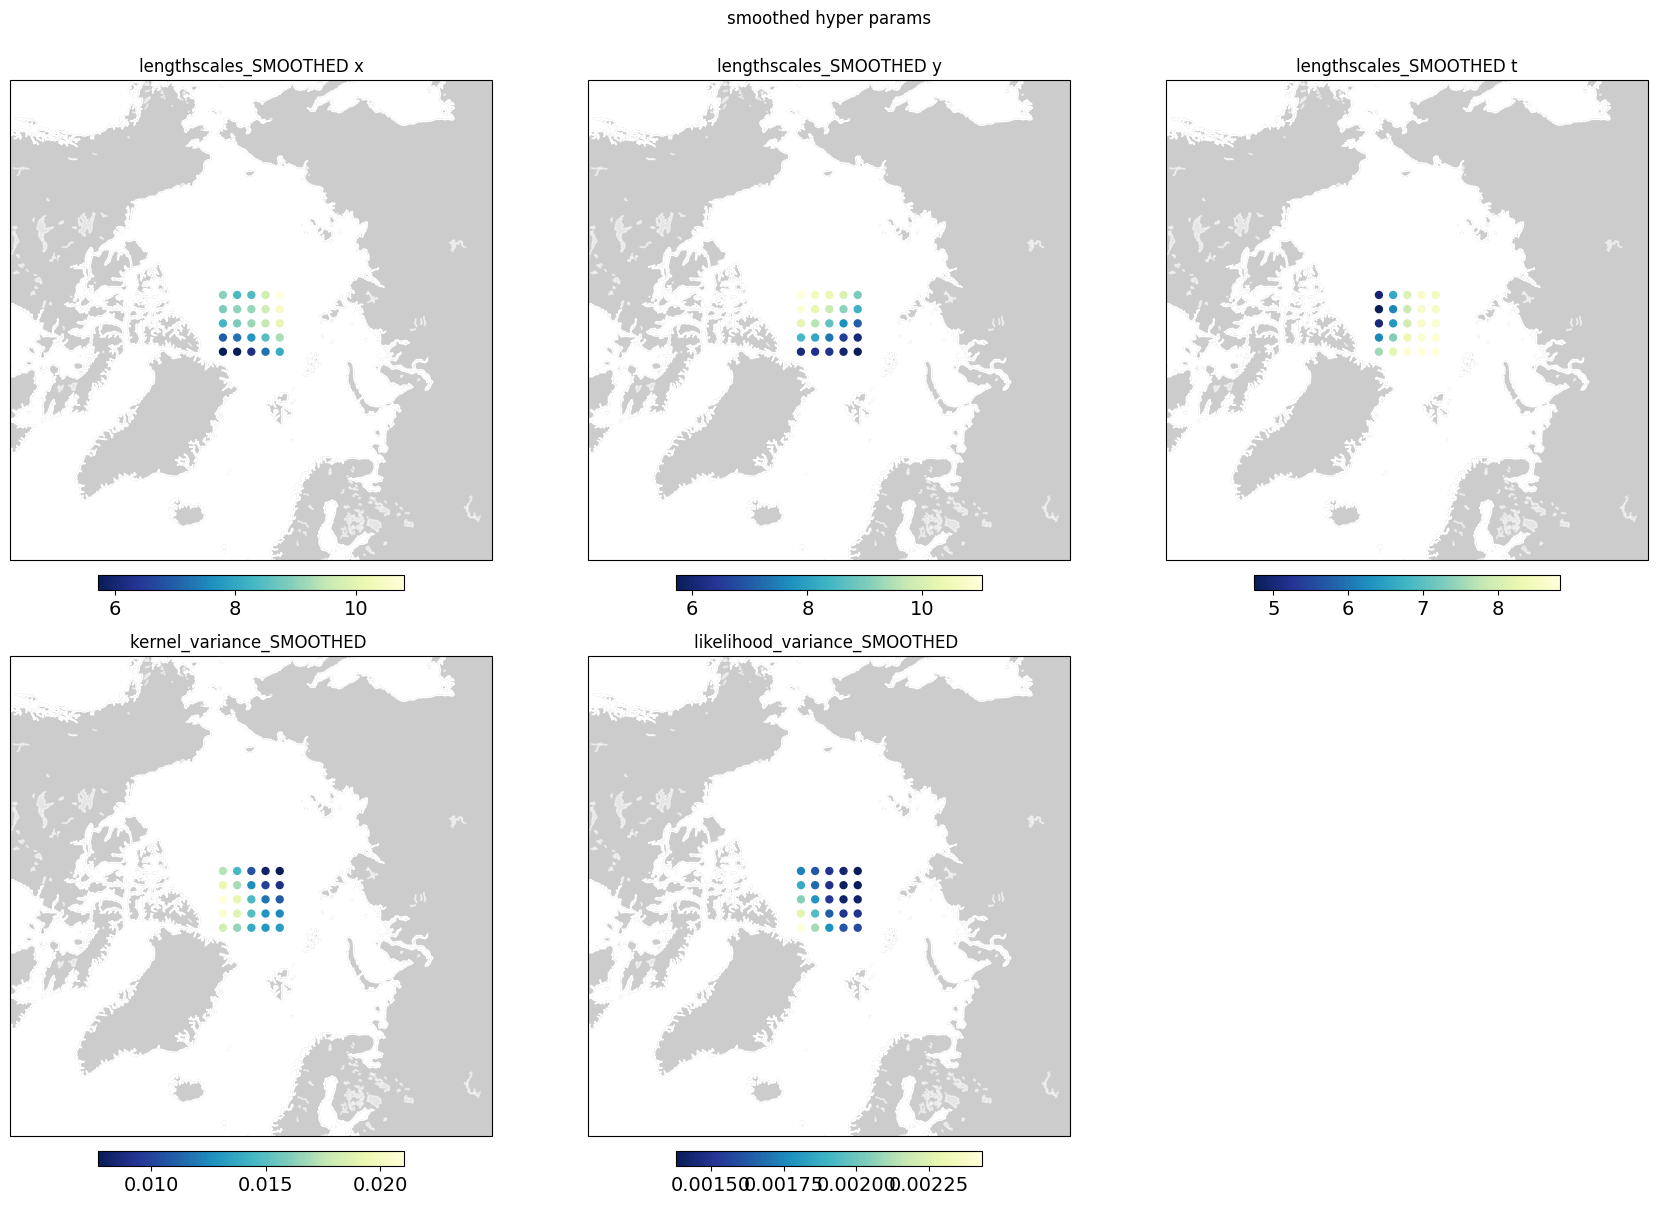

In [38]:
# extract, store in dict
dfs, oi_config = get_results_from_h5file(store_path)

fig = plot_hyper_parameters(dfs,
                            coords_col=oi_config[0]['data']['coords_col'],  # ['x', 'y', 't']
                            row_select=None,
                            table_names=["lengthscales", "kernel_variance", "likelihood_variance"],
                            table_suffix=smooth_config["table_suffix"],
                            plot_template=plot_template,
                            plots_per_row=3,
                            suptitle="smoothed hyper params",
                            qvmin=0.01,
                            qvmax=0.99)

plt.tight_layout()
plt.show()

# get weighted combinations predictions and plot

#✨**Combining and plotting GPSat predictions**
This section extracts the predictions generated using the smoothed hyperparameters and combines overlapping estimates from neighbouring local experts. Gaussian distance-based weighting is used, giving greater influence to experts closer to each prediction location. The weighting lengthscale is 100 km, half the 200 km inference radius. Both predicted values and prediction variances are included in the weighting procedure. The resulting predictions are converted into geographical coordinates and displayed on an Arctic map. Unlike the earlier hyperparameter plots, this map shows the actual reconstructed values estimated by GPSat.

Scientific takeaway: This section produces a combined spatial reconstruction from multiple local Gaussian Process models. For my dissertation, the important next step is evaluating whether such reconstructions accurately reproduce the short-term variability observed independently by SWOT, rather than simply producing smooth-looking maps.

One thing to watch: This code does not explicitly select a particular prediction date before plotting. If your results contain multiple times, it's worth checking which dates are represented in the map.

'data_select': 0.003 seconds
'load': 0.003 seconds
'plot_pcolormesh': 0.042 seconds


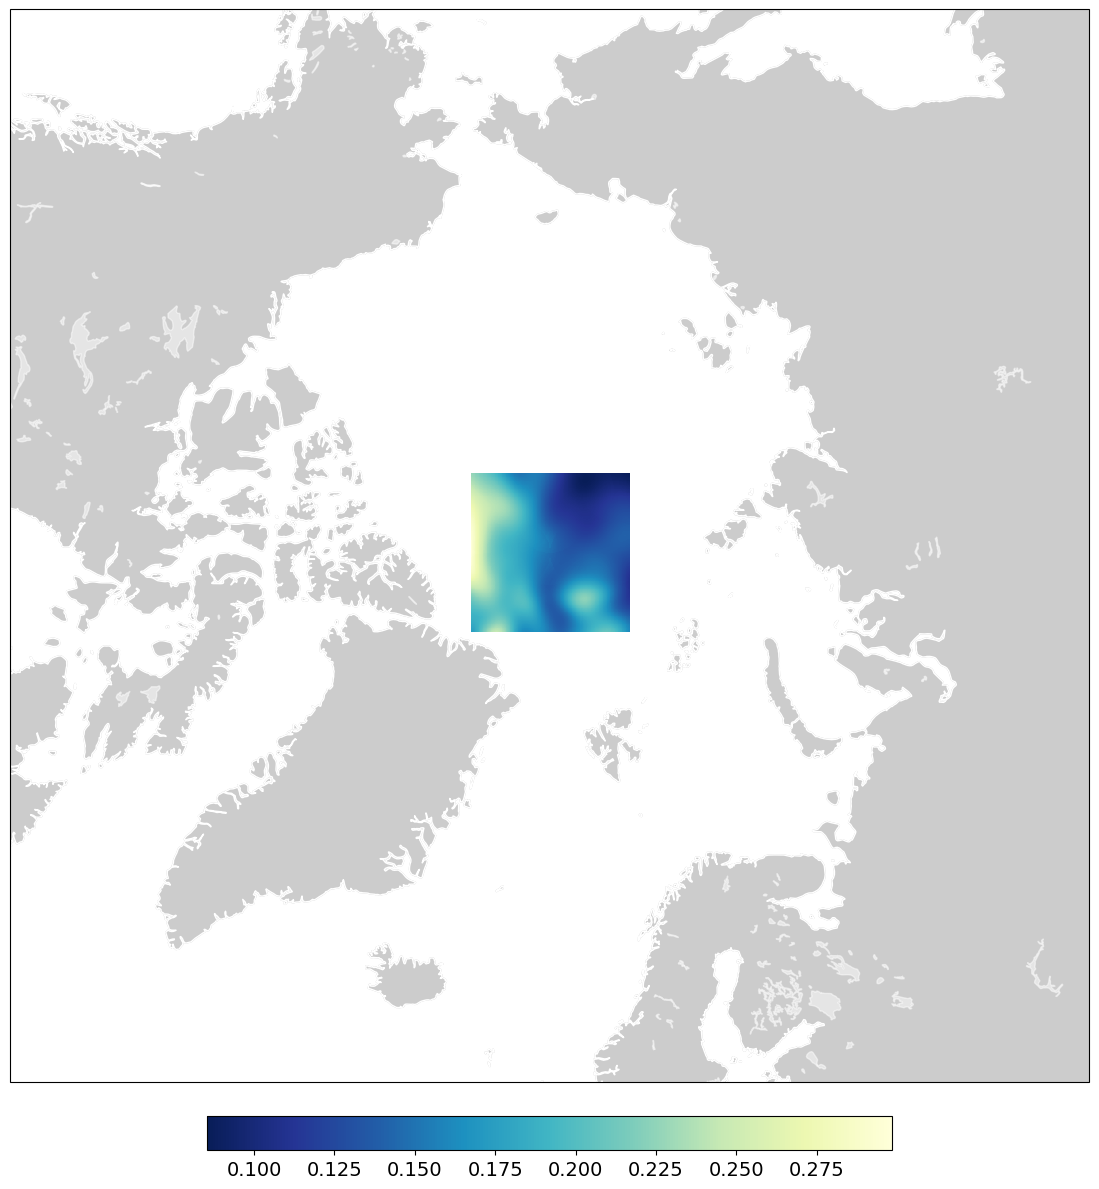

In [39]:

plt_data = dfs["preds" + smooth_config["table_suffix"]]

weighted_values_kwargs = {
    "ref_col": ["pred_loc_x", "pred_loc_y", "pred_loc_t"],
    "dist_to_col": ["x", "y", "t"],
    "val_cols": ["f*", "f*_var"],
    "weight_function": "gaussian",
    "lengthscale": inference_radius/2
}
plt_data = get_weighted_values(df=plt_data, **weighted_values_kwargs)

plt_data['lon'], plt_data['lat'] = EASE2toWGS84(plt_data['pred_loc_x'], plt_data['pred_loc_y'])

fig = plt.figure(figsize=(12, 12))
ax = fig.add_subplot(1, 1, 1, projection=get_projection(projection))
plot_pcolormesh_from_results_data(ax=ax,
                                  dfs={"preds": plt_data},
                                  table='preds',
                                  val_col="f*",
                                  x_col='pred_loc_x',
                                  y_col='pred_loc_y',
                                  fig=fig)
plt.tight_layout()
plt.show()